# 05 · Causal Machine Learning

| | Traditional ML | Causal ML |
|---|---|---|
| Question | *Who is likely to churn?* | *Whose churn changes **because** we contact them?* |
| Target | `P(y = 1 \| X)` | `τ(x) = E[Y(1) − Y(0) \| X = x]`, the **conditional average treatment effect (CATE)** |
| Observable? | Yes: we see who churned | **No**: nobody's `Y(1) − Y(0)` is ever observed |
| Validation | Compare predictions with outcomes | Only indirectly, by comparing treated vs control *groups* (notebook 06) |

The last row matters most. A churn model can be checked customer by customer. An estimated
individual effect cannot, because it is a model's estimate of a quantity that is never observed.

**Meta-learners** turn ordinary prediction models into CATE estimators:

* **S-learner:** one model `f(X, t)`, then `τ̂(x) = f(x, 1) − f(x, 0)`.
* **T-learner:** two models, `μ₁` fitted on treated and `μ₀` on control customers, then
  `τ̂(x) = μ₁(x) − μ₀(x)`.
* **X-learner** (Künzel et al., 2019): an extension of the T-learner designed for **unbalanced
  arms**. It imputes individual effects using the *other* arm's model, regresses them on `X`,
  and weights the two resulting estimates by the propensity score. It is included because this
  experiment has 3× more treated than control customers, which is exactly the case it was built for.

Every estimate is **cross-fitted**: each customer's CATE comes from models trained on the other
80% of customers, so later evaluation is out-of-sample.

Sign convention: `τ̂ < 0` means contact is estimated to **reduce** that customer's churn probability.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src.functions import (AQUA, BLUE, GREY, INK_2, ORANGE, OUTCOME, TREATMENT, area_vs_random,
                           feature_lists, load_data, make_gbm_classifier, make_gbm_regressor,
                           make_logit, make_preprocessor, make_synthetic, s_learner, savefig,
                           set_style, t_learner, uplift_by_group, x_learner)

set_style()
PROCESSED = ROOT / "data" / "processed"

## 1. Do these methods work at all? A test on synthetic data with a known answer

On real data the true CATE is unknown, so a disappointing result could mean either "there is no
heterogeneity" or "the method failed". To tell these apart, the same pipeline is first run on
**simulated experiments** with a known, planted effect. The simulation mimics the real data:
12,000 customers, 76% treated, ~3% churn. Contact strongly reduces churn for one segment and
slightly increases it for another ("sleeping dogs"). Two scenarios are simulated:

* **strong:** an average effect of about −1 pp, with large differences between segments;
* **realistic:** the same structure scaled down so the average effect is about −0.3 pp, matching
  the real experiment.

Two scores are reported. The first is the **correlation** between estimated and true CATE, which
is only possible because the truth is known. The second is the **uplift-curve area versus random
targeting** (notebook 06), the metric that can also be computed on real data. That area is shown
alongside the area achieved by the *true* CATE, the best ranking possible.

In [2]:
def run_learners(X, t, y, e, seed=0):
    return {
        "S-learner · GBM": s_learner(make_gbm_classifier, X, t, y, seed=seed)[2],
        "S-learner · logistic + t×X": s_learner(lambda: make_logit(0.05), X, t, y, seed=seed,
                                                interactions=True)[2],
        "T-learner · GBM": t_learner(make_gbm_classifier, X, t, y, seed=seed)[2],
        "X-learner · GBM": x_learner(make_gbm_classifier, make_gbm_regressor, X, t, y, e, seed=seed),
    }

rows = []
for scenario, scale in [("strong", 1.0), ("realistic", 0.15)]:
    for rep in range(3):
        Xs, ts, ys, tau = make_synthetic(effect_scale=scale, seed=100 + rep)
        oracle = area_vs_random(-tau, ys, ts)
        for name, cate in run_learners(Xs, ts, ys, ts.mean(), seed=rep).items():
            corr = np.corrcoef(cate, tau)[0, 1] if cate.std() > 0 else np.nan
            rows.append({"scenario": scenario, "rep": rep, "learner": name,
                         "true ATE (pp)": 100 * tau.mean(), "corr(τ̂, τ)": corr,
                         "uplift area": area_vs_random(-cate, ys, ts), "oracle area": oracle})
sim = pd.DataFrame(rows)
(sim.groupby(["scenario", "learner"], sort=False)
    [["true ATE (pp)", "corr(τ̂, τ)", "uplift area", "oracle area"]].mean().round(4))

true ATE (pp)  corr(τ̂, τ)  uplift area  \
scenario  learner                                                               
strong    S-learner · GBM                   -1.0259       0.7152       0.0051   
          S-learner · logistic + t×X        -1.0259       0.6982       0.0049   
          T-learner · GBM                   -1.0259       0.5536       0.0046   
          X-learner · GBM                   -1.0259       0.5768       0.0038   
realistic S-learner · GBM                   -0.2963       0.3553      -0.0007   
          S-learner · logistic + t×X        -0.2963      -0.0139      -0.0008   
          T-learner · GBM                   -0.2963       0.0819       0.0002   
          X-learner · GBM                   -0.2963       0.1420       0.0000   

                                      oracle area  
scenario  learner                                  
strong    S-learner · GBM                  0.0070  
          S-learner · logistic + t×X       0.0070  
          T-learner · GBM                  0.0070  
          X-learner · GBM                  0.0070  
realistic S-learner · GBM                  0.0016  
          S-learner · logistic + t×X       0.0016  
          T-learner · GBM                  0.0016  
          X-learner · GBM                  0.0016

**What the simulation shows**

* **Strong scenario:** all four learners recover the planted heterogeneity (correlation with the
  truth 0.55–0.72), and their uplift areas reach 55–75% of the oracle's. The pipeline and the
  evaluation code work. With a strong signal, the simple GBM S-learner is actually the best.
* **Realistic scenario:** with a −0.3 pp average effect and ~400 churners, recovery collapses.
  The best correlation with the truth is ~0.35, and **no learner's ranking beats random
  targeting** (uplift areas ≈ 0), even though the true CATE would achieve a clearly positive area.
  Real, exploitable heterogeneity exists here by construction, and the data is simply too small to
  find it.

> **Expectation for the real data:** if the real effect is as weak as notebooks 03–04 suggest,
> the meta-learners should be expected to find little reliable heterogeneity *even if it exists*.
> A weak result would therefore be evidence of **insufficient data**, not evidence that
> every customer responds identically.

## 2. Real data: fit the learners

In [3]:
df = load_data()
num, cat = feature_lists(df)
X = make_preprocessor(num, cat).fit_transform(df)
t, y = df[TREATMENT].to_numpy(), df[OUTCOME].to_numpy()
e = pd.read_parquet(PROCESSED / "propensity.parquet")["propensity"].to_numpy()
print(f"Feature matrix: {X.shape[0]:,} customers × {X.shape[1]} features")

SEEDS = range(5)
runs = {s: run_learners(X, t, y, e, seed=s) for s in SEEDS}
learners = list(runs[0])

Feature matrix: 11,896 customers × 310 features


Each learner is fitted five times with different random fold assignments. A customer's CATE
estimate should not depend much on which other customers happened to share their training folds.
How much it *does* change is a direct measure of how much of the estimate is noise.

## 3. Distribution of estimated effects

In [4]:
desc = []
for name in learners:
    c = np.mean([runs[s][name] for s in SEEDS], axis=0)  # seed-averaged estimate
    desc.append({"learner": name, "mean τ̂ (pp)": 100 * c.mean(), "sd τ̂ (pp)": 100 * c.std(),
                 "p5 (pp)": 100 * np.quantile(c, 0.05), "p95 (pp)": 100 * np.quantile(c, 0.95),
                 "share τ̂ < 0": (c < 0).mean()})
pd.DataFrame(desc).set_index("learner").round(3)

,mean τ̂ (pp),sd τ̂ (pp),p5 (pp),p95 (pp),share τ̂ < 0
learner,,,,,
S-learner · GBM,0.001,0.008,0.000,0.000,0.000
S-learner · logistic + t×X,-0.047,6.875,-6.711,7.244,0.635
T-learner · GBM,0.616,3.221,-2.499,5.135,0.319
X-learner · GBM,-0.339,2.882,-5.653,3.794,0.502


* The **GBM S-learner** estimates a CATE of exactly zero for almost every customer. Unlike in the
  strong simulation, the trees never find it worthwhile to split on `t`, so the model behaves as if
  treatment does not exist. This *regularisation bias towards zero* is a known weakness of
  S-learners when the treatment signal is weak.
* The **logistic S-learner with t × X interactions** (≈ 620 coefficients for 408 events)
  overfits badly despite the L2 penalty. Some customers get "effects" of ±80 pp, which is not
  plausible for a phone call.
* The **T-learner's** average CATE is **+0.6 pp**, while the experiment's ATE is −0.28 pp. This
  happens because the two outcome models are regularised differently: the control model sees
  one third of the data and shrinks more towards the base rate. Their difference is therefore biased,
  and much of its spread comes from the noisy control-arm model (only ~85 churners per training fold).
* The **X-learner's** average (−0.34 pp) is consistent with the experimental ATE. Its
  distribution is still wide (5th–95th percentile ≈ −5.7 to +3.8 pp).

## 4. Are the estimates stable?

In [5]:
stab = []
for name in learners:
    mats = np.array([runs[s][name] for s in SEEDS])
    if (mats == 0).mean() > 0.5:  # degenerate: CATE identically zero for most customers
        stab.append({"learner": name, "mean rank corr. between seeds": np.nan,
                     "top-20% overlap between seeds": np.nan, "sign agreement": np.nan})
        continue
    rc = [stats.spearmanr(mats[i], mats[j])[0] for i in SEEDS for j in SEEDS if i < j]
    k = int(0.2 * len(y))
    tops = [set(np.argsort(m)[:k]) for m in mats]  # most negative CATE = largest churn reduction
    ov = [len(tops[i] & tops[j]) / k for i in SEEDS for j in SEEDS if i < j]
    signs = np.sign(mats)
    agree = (np.abs(signs.sum(axis=0)) == len(SEEDS)).mean()
    stab.append({"learner": name, "mean rank corr. between seeds": np.mean(rc),
                 "top-20% overlap between seeds": np.mean(ov), "sign agreement": agree})
pd.DataFrame(stab).set_index("learner").round(3)

,mean rank corr. between seeds,top-20% overlap between seeds,sign agreement
learner,,,
S-learner · GBM,NaN,NaN,NaN
S-learner · logistic + t×X,0.661,0.657,0.584
T-learner · GBM,0.566,0.539,0.467
X-learner · GBM,0.646,0.571,0.464


In [6]:
avg = {name: np.mean([runs[s][name] for s in SEEDS], axis=0) for name in learners}
agree = pd.DataFrame({k: v for k, v in avg.items() if v.std() > 0}).corr(method="spearman")
agree.round(2)

,S-learner · GBM,S-learner · logistic + t×X,T-learner · GBM,X-learner · GBM
S-learner · GBM,1.00,0.02,0.06,0.02
S-learner · logistic + t×X,0.02,1.00,0.37,0.34
T-learner · GBM,0.06,0.37,1.00,0.53
X-learner · GBM,0.02,0.34,0.53,1.00


**Stability findings**

* Re-running the *same* learner with a different fold split gives rank correlations of only
  **0.57–0.66**. The overlap between the "top 20% most persuadable" lists from two runs is only
  **54–66%**. If a list of customers to call can change this much because
  of a random seed, it should not drive a business decision without further validation.
* *Sign agreement* is the share of customers whose estimated effect has the same sign under all
  five seeds. For the T- and X-learners it is **under 50%**: most customers flip between "helped"
  and "harmed" across reruns.
* Different learners agree only weakly with each other (rank correlations 0.3–0.5, table above).
  The degenerate GBM S-learner is uncorrelated with everything.

For the targeting analysis, each learner's **five-seed average** is used. Averaging over fold
assignments is a form of bagging that reduces variance. It does not remove bias.

In [7]:
cate_out = pd.DataFrame({
    "cate_s_gbm": avg["S-learner · GBM"],
    "cate_s_logit": avg["S-learner · logistic + t×X"],
    "cate_t_gbm": avg["T-learner · GBM"],
    "cate_x_gbm": avg["X-learner · GBM"],
})
cate_out.to_parquet(PROCESSED / "cate.parquet", index=False)
cate_out.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
cate_s_gbm,11896.0,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000,0.0031
cate_s_logit,11896.0,-0.0005,0.0688,-0.8275,-0.0084,-0.0011,0.0033,0.9371
cate_t_gbm,11896.0,0.0062,0.0322,-0.3463,-0.0011,0.0022,0.0086,0.4063
cate_x_gbm,11896.0,-0.0034,0.0288,-0.1569,-0.0193,-0.0001,0.0163,0.0974


## 5. Figure: estimated individual effects and their stability

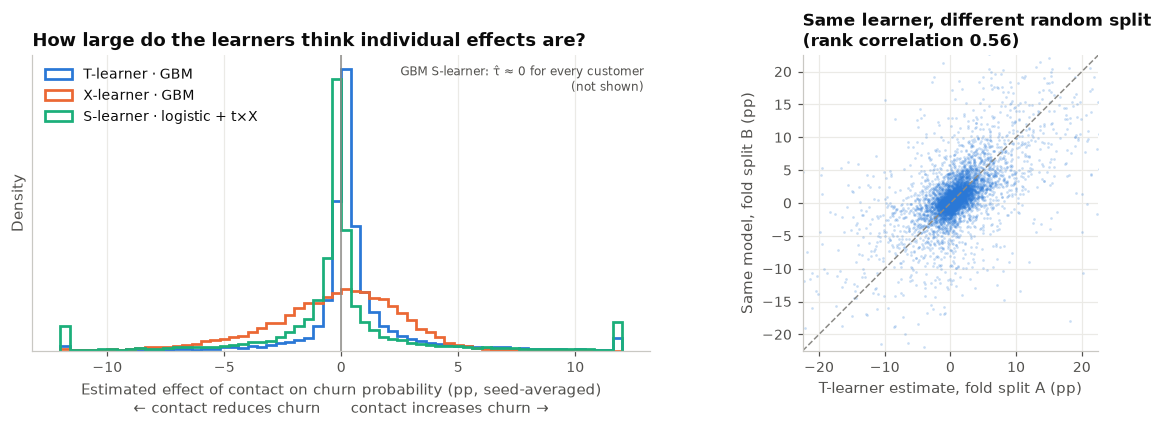

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})

bins = np.linspace(-12, 12, 61)
for name, colour in [("T-learner · GBM", BLUE), ("X-learner · GBM", ORANGE),
                     ("S-learner · logistic + t×X", AQUA)]:
    a1.hist(np.clip(100 * avg[name], -12, 12), bins=bins, histtype="step", linewidth=1.8,
            color=colour, label=name, density=True)
a1.axvline(0, color=GREY, linewidth=1)
a1.set_xlabel("Estimated effect of contact on churn probability (pp, seed-averaged)\n"
              "← contact reduces churn      contact increases churn →")
a1.set_ylabel("Density")
a1.set_yticks([])
a1.set_title("How large do the learners think individual effects are?")
a1.legend(loc="upper left")
a1.text(0.99, 0.97, "GBM S-learner: τ̂ ≈ 0 for every customer\n(not shown)",
        transform=a1.transAxes, ha="right", va="top", fontsize=8, color=INK_2)

c0, c1 = 100 * runs[0]["T-learner · GBM"], 100 * runs[1]["T-learner · GBM"]
lim = np.quantile(np.abs(np.r_[c0, c1]), 0.995)
a2.scatter(c0, c1, s=3, alpha=0.25, color=BLUE, linewidths=0, rasterized=True)
a2.plot([-lim, lim], [-lim, lim], color=GREY, linewidth=1, linestyle="--")
a2.set_xlim(-lim, lim)
a2.set_ylim(-lim, lim)
a2.set_aspect("equal")
r_s = stats.spearmanr(c0, c1)[0]
a2.set_xlabel("T-learner estimate, fold split A (pp)")
a2.set_ylabel("Same model, fold split B (pp)")
a2.set_title(f"Same learner, different random split\n(rank correlation {r_s:.2f})", fontsize=11)
plt.tight_layout()
savefig(fig, "fig6_cate_distribution")

**Reading the figure.** *Left:* the learners estimate individual effects spread over many
percentage points, an order of magnitude wider than the average effect (−0.3 pp) and wider than
anything the subgroup analysis in notebook 04 could confirm. The logistic S-learner has the
widest tails (clipped at ±12 pp here). *Right:* each dot is a customer,
estimated by the same T-learner trained on two different random fold splits. If the estimates
were reliable, the dots would sit on the diagonal. The wide cloud shows how much of an individual
estimate is noise.

## Summary

* On simulated data with strong heterogeneity, all learners recover it. The method and code are
  sound. When the simulated effect is scaled down to the size seen in this experiment, no learner
  beats random targeting.
* The learners fail in instructive ways on the real data. The GBM S-learner shrinks every effect to
  zero, the logistic S-learner overfits, and the T-learner is biased (mean +0.6 pp vs ATE −0.3 pp).
  The X-learner, designed for unbalanced arms, is the most coherent of the four.
* On the real data, the learners produce widely spread individual estimates that are **unstable
  across random splits** and only weakly consistent between learners. This is the signature of
  estimating a small effect from about 400 events, not of strong, real heterogeneity.
* Whether the rankings carry *any* usable signal can only be judged by evaluating them on
  outcomes: do customers ranked as most persuadable actually show a larger treated-vs-control
  churn gap? That is the subject of notebook 06.